In [1]:
from lsst.daf.butler import Butler
import lsst.summit.utils.plotting as splot
from lsst.afw.math import binImage
from lsst.daf.butler import Butler
from lsst.pipe.tasks.visualizeVisit import VisualizeMosaicExpConfig, VisualizeMosaicExpTask
import matplotlib.pyplot as plt
import numpy as np
from tqdm import tqdm, trange
from lsst.summit.utils.utils import getCameraFromInstrumentName


100%|██████████| 6/6 [00:06<00:00,  1.09s/it]


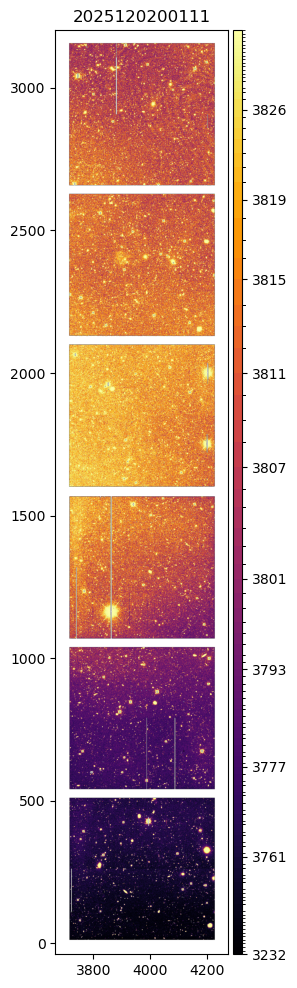

In [7]:
repo = "embargo"
#repo = '/repo/main'
butler = Butler(config=repo,instrument='LSSTCam')
coll=["LSSTCam/runs/nightlyValidation"]  #can also be a list of multiple collections
binning = 8  #very useful if you want to plot full focal plane images
badMaskNames  = ["NO_DATA", "DETECTED", "DETECTED_NEGATIVE", "SAT", "BAD", "INTRP", "CR",]
exp=2025120200111

# detects = range(0,189)
detects=[10,13,16,46,49,52] #use this to select specific detectors
pIsrImsBinned = []
ids = []
for i in tqdm(detects):
    dataId = {"instrument": "LSSTCam", "exposure":exp , "detector": i}
    # dataId = {"instrument": "LSSTCam", "visit":exp , "detector": i}   #use this for preliminary_visit data
    try:
        im = butler.get("post_isr_image", dataId=dataId, collections=coll)
        # im = butler.get("preliminary_image_data", dataId=dataId, collections=coll)  #use this for preliminary_visit data
        bad_mask_bit_mask = im.mask.getPlaneBitMask(badMaskNames)          #masking bad pixels, not necessary but nice
        msk = (im.mask.array.astype(int) & bad_mask_bit_mask) != 0
        im.getMaskedImage().image.array[msk] = np.nan                      # Try removing detections &c.
        ids.append(i)
        pIsrImsBinned.append(binImage(im.getMaskedImage(), binning))       #by default this makes a mean bining, 
                                                                           #it does not associate the sum of the 
                                                                           #pixels to the new superpixel
    except:
        print(f' Detector{i} is missing')
        continue
        
camera = getCameraFromInstrumentName('LSSTCam')
plt.close('all')
mosConfig = VisualizeMosaicExpConfig()
mosConfig.binning = binning
mosTask = VisualizeMosaicExpTask(config=mosConfig)

pIsrMosaic = mosTask.run(pIsrImsBinned, camera, inputIds=ids).outputData
figure=plt.figure(figsize=(6,12))

a=splot.plot(pIsrMosaic.array, stretch='ccs',cmap='inferno', figure=figure)
ax=figure.axes[0]
ax.set_title(f'{exp}')


valid_rows = np.where(~np.isnan(pIsrMosaic.array).all(axis=1))[0]
valid_cols = np.where(~np.isnan(pIsrMosaic.array).all(axis=0))[0]

# Extract boundaries
row_min, row_max = valid_rows[0], valid_rows[-1]
col_min, col_max = valid_cols[0], valid_cols[-1]




ax.set_xlim(col_min-50,col_max+50)
ax.set_ylim(row_min-50,row_max+50)
# plt.savefig(f'{exp}.png')
plt.show()
del pIsrMosaic #ised to free some ram, images are quite heavy
